# Clasificación: Logística Ridge

### Imports y Configuración

In [1]:
import sys
sys.path.append("/workspace/src")

import pandas as pd
import matplotlib.pyplot as plt

from EstiloGraficos import aplicar_estilo

# Misma paleta y estilo que el dashboard (components/plotly_theme.py)
aplicar_estilo()

# Textos largos completos en las tablas (criterio de selección, hiperparámetros)
pd.set_option("display.max_colwidth", None)

from Modelado import (
    SEED, USAR_GPU, GPU_DISPOSITIVOS, NOMBRES_CLF, ESTRATEGIAS, N_ITER_FASE1,
    cargar_split, separar_x_y, crear_cv, dispositivo_modelo, coeficientes_logistica, verificar_smotenc,
    describir_espacio, ejecutar_fase1, formatear_tabla_cv, graficar_estrategias, elegir_mejor, guardar_fase1,
    formatear_hiperparametros, tabla_hiperparametros,
)

CLAVE = "ridge"

In [2]:
pd.Series({
    "USAR_GPU": USAR_GPU,
    "GPU detectada por librería": ", ".join(f"{lib}: {disp}" for lib, disp in GPU_DISPOSITIVOS.items() if disp) or "ninguna",
    "Dispositivo de entrenamiento": dispositivo_modelo(CLAVE),
}, name=NOMBRES_CLF[CLAVE]).to_frame()

,Logística Ridge (L2)
USAR_GPU,True
GPU detectada por librería,"xgboost: cuda, catboost: GPU, lightgbm: cuda"
Dispositivo de entrenamiento,CPU


### Datos: Split y Folds

In [3]:
df = pd.read_csv('/workspace/data/raw/screen_time_mental_health.csv')

df_train, _ = cargar_split(df)   # el test no se usa en esta fase
X_train, y_train = separar_x_y(df_train)
cv = crear_cv(SEED)

pd.DataFrame({
    "Filas": [len(X_train)],
    "Predictores": [X_train.shape[1]],
    "Deprimidos": [int(y_train.sum())],
    "Prevalencia": [round(y_train.mean(), 3)],
}, index=pd.Index(["Train"], name="Conjunto"))

,Filas,Predictores,Deprimidos,Prevalencia
Conjunto,,,,
Train,3848,6,630,0.164


### Estrategias de Manejo del Desbalance

Se comparan las tres estrategias de [manejo del desbalance](#mod-desbalance). En la logística Ridge, los pesos de clase se aplican con `class_weight="balanced"`.

In [4]:
tabla_clases, tabla_sexo = verificar_smotenc(X_train, y_train, seed=SEED)
display(tabla_clases)
display(tabla_sexo)

✓ sex solo toma los valores ['Boy', 'Girl']
✓ Clases balanceadas: {0: 3218, 1: 3218}


,Antes,Después,Sintéticos
Deprimido,,,
0,3218,3218,0
1,630,3218,2588


Deprimido,0,1
Sexo,,
Boy,1789,770
Girl,1429,2448


### Espacio de Búsqueda

Se exploraron 10 valores aleatorios de `C` por estrategia, en escala logarítmica entre 0.001 y 100. `C` es el inverso de la fuerza de regularización: valores pequeños encogen más los coeficientes hacia cero.

In [5]:
describir_espacio(CLAVE).style.set_caption(f"Combinaciones por estrategia: {N_ITER_FASE1[CLAVE]}")

,Valores
Hiperparámetro,
C,log-uniforme entre 0.001 y 100


### Validación Cruzada por Estrategia

In [6]:
tabla, pipelines, hiperparametros = ejecutar_fase1(CLAVE, X_train, y_train, cv, seed=SEED)

✓ Nativo (sin balanceo)  PR-AUC = 0.3927 ± 0.0435  (4 s)
✓ Pesos de clase         PR-AUC = 0.3937 ± 0.0439  (0 s)
✓ SMOTENC                PR-AUC = 0.3926 ± 0.0468  (1 s)


In [7]:
vista = formatear_tabla_cv(tabla)
vista["Tiempo (s)"] = tabla["Tiempo (s)"].round(1)
vista.rename(index=ESTRATEGIAS)

,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy,Tiempo (s)
Estrategia,,,,,,,
Nativo (sin balanceo),0.393 ± 0.043,0.756 ± 0.031,0.572 ± 0.050,0.117 ± 0.027,0.193 ± 0.036,0.840 ± 0.002,4.0
Pesos de clase,0.394 ± 0.044,0.756 ± 0.031,0.312 ± 0.031,0.648 ± 0.048,0.421 ± 0.038,0.708 ± 0.025,0.3
SMOTENC,0.393 ± 0.047,0.755 ± 0.033,0.318 ± 0.030,0.630 ± 0.054,0.423 ± 0.039,0.718 ± 0.021,0.7


Las tres estrategias obtienen prácticamente la misma PR-AUC (0.393, 0.394 y 0.393, con desviaciones de 0.043 a 0.047 que se solapan por completo) y la misma ROC-AUC (0.756 ± 0.031, 0.756 ± 0.031 y 0.755 ± 0.033). La capacidad discriminativa existe, pero es modesta.

Las diferencias aparecen en las demás métricas, calculadas con el umbral de 0.5. El nativo tiene la precision más alta (0.572 ± 0.050), pero su recall de 0.117 ± 0.027 implica que se le escapa casi el 90% de los casos, lo que deja el F1 en 0.193 ± 0.036. Su accuracy de 0.840 ± 0.002 es la más alta, pero apenas supera la de predecir siempre “no deprimido” (1 − 0.164 = 0.836), así que no refleja capacidad predictiva.

El modelo con pesos de clase alcanza un recall de 0.648 ± 0.048 con una precision de 0.312 ± 0.031, y SMOTENC un recall de 0.630 ± 0.054 con una precision de 0.318 ± 0.030. Ambos llegan a un F1 equivalente (0.421 ± 0.038 y 0.423 ± 0.039), y su accuracy baja a 0.708 ± 0.025 y 0.718 ± 0.021 por el aumento de falsos positivos en la clase mayoritaria.

In [8]:
# Mejores hiperparámetros por estrategia
tabla_hiperparametros(hiperparametros)

,C
Estrategia,
Nativo (sin balanceo),0.074590
Pesos de clase,0.074590
SMOTENC,0.006025


El nativo y el de pesos de clase eligieron el mismo `C` ≈ 0.075, una regularización moderada. SMOTENC eligió un `C` unas 12 veces menor (≈ 0.006), es decir, una penalización mucho más fuerte, probablemente para contrarrestar el ruido de los casos sintéticos. Como la PR-AUC apenas cambia entre estrategias, la búsqueda parece estar en una zona plana donde valores de `C` muy distintos dan resultados equivalentes.

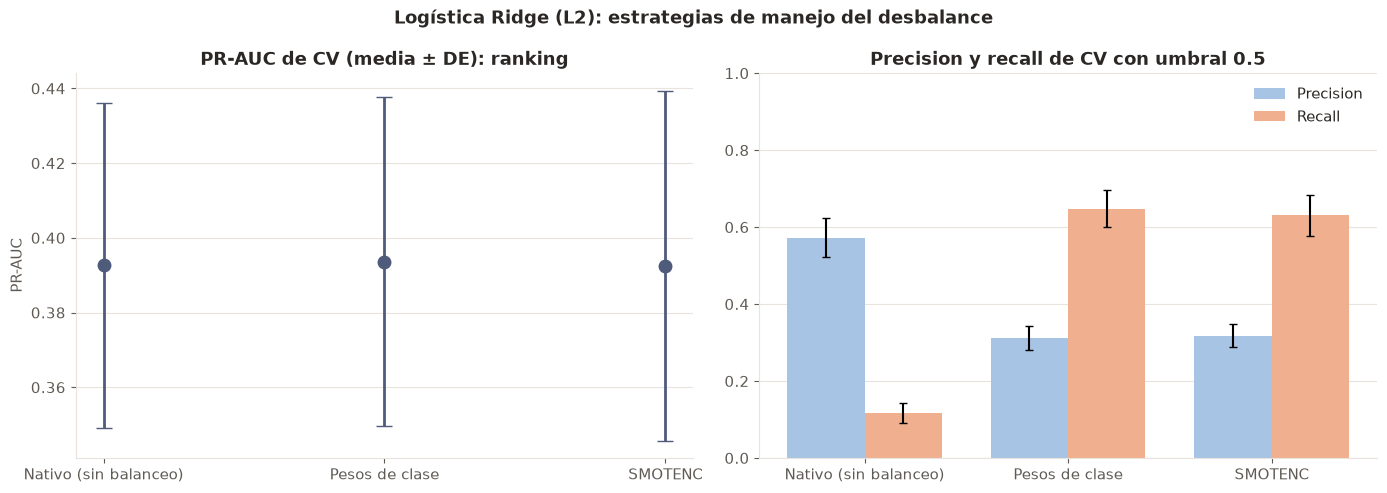

In [9]:
fig = graficar_estrategias(tabla, NOMBRES_CLF[CLAVE])
plt.show()

La gráfica confirma que las tres estrategias producen esencialmente el mismo modelo. La PR-AUC media es prácticamente idéntica (~0.39) y las barras de desviación se solapan por completo, así que ni los pesos de clase ni SMOTENC mejoran la capacidad de la Ridge para ordenar los positivos por encima de los negativos. Lo que cambia es el punto de operación con el umbral fijo de 0.5: el nativo casi no predice la clase minoritaria (precision ~0.57, recall ~0.12), mientras que los pesos de clase y SMOTENC desplazan las probabilidades hacia la clase positiva y llevan el recall a ~0.65 y ~0.63 a costa de una precision de ~0.31 y ~0.32.

**Coeficientes por estrategia** (variables estandarizadas)

In [10]:
pd.DataFrame({
    ESTRATEGIAS[estrategia]: coeficientes_logistica(pipeline).set_index("Variable")["Coeficiente"]
    for estrategia, pipeline in pipelines.items()
}).round(3)

,Nativo (sin balanceo),Pesos de clase,SMOTENC
Variable,,,
sleep_quality_index,0.521,0.565,0.620
avg_sleep_hours,-0.192,-0.191,-0.219
midsleep_weekend_hours,0.170,0.211,0.108
social_jetlag_hours,-0.028,-0.054,0.039
screen_time_index,0.065,0.092,0.083
sex_Girl,0.946,1.020,0.760


Entre el nativo y los pesos de clase, los coeficientes son estables en signo y orden de magnitud. Ser mujer (`sex_Girl`, 0.95 y 1.02) es el predictor con mayor coeficiente, seguido de `sleep_quality_index` (0.52 y 0.57); más horas de sueño reducen el riesgo (`avg_sleep_hours`, ≈ −0.19), y un punto medio de sueño más tardío el fin de semana (`midsleep_weekend_hours`, 0.17 y 0.21) y el tiempo de pantalla (`screen_time_index`, 0.07 y 0.09) lo aumentan levemente. El coeficiente de `sex_Girl` no es directamente comparable con los demás, porque es una variable dummy (0/1) y no está estandarizada.

Con SMOTENC, la regularización más fuerte (`C` ≈ 0.006) encoge `sex_Girl` (0.76) y `midsleep_weekend_hours` (0.11), mientras que `sleep_quality_index` sube a 0.62. El coeficiente de `social_jetlag_hours`, cercano a cero en todas las estrategias, cambia de signo (de −0.03 y −0.05 a 0.04), lo que indica que su efecto no es distinguible de cero.

### Selección del Mejor Modelo Logística Ridge

In [11]:
estrategia_ganadora, explicacion = elegir_mejor(tabla)

pd.Series({
    "Estrategia ganadora": ESTRATEGIAS[estrategia_ganadora],
    "PR-AUC de CV": f"{tabla.loc[estrategia_ganadora, 'PR-AUC media']:.4f} ± {tabla.loc[estrategia_ganadora, 'PR-AUC DE']:.4f}",
    "Hiperparámetros": formatear_hiperparametros(hiperparametros[estrategia_ganadora]),
    "Criterio": explicacion,
}, name=NOMBRES_CLF[CLAVE]).to_frame()

,Logística Ridge (L2)
Estrategia ganadora,Pesos de clase
PR-AUC de CV,0.3937 ± 0.0439
Hiperparámetros,C=0.07459
Criterio,Se elige 'pesos': tiene la mayor PR-AUC media de CV (0.3937 ± 0.0439).


Se eligen los pesos de clase, que tienen la PR-AUC media más alta (0.3937 ± 0.0439). Su ventaja sobre el nativo (0.0010) y SMOTENC (0.0011) es mucho menor que la desviación entre folds, así que en la práctica las tres estrategias son equivalentes. Con umbral 0.5 alcanza un recall de 0.648 con una precision de 0.312, aunque el umbral de operación se optimiza en la fase 3.

### Guardado

In [12]:
ganador = guardar_fase1(
    CLAVE, tabla, estrategia_ganadora, pipelines[estrategia_ganadora],
    hiperparametros[estrategia_ganadora], explicacion,
)